# JS07: Lab 1

Klasterisasi Iris dengan K Means.

## Langkah 0: Persiapan dataset

Iris.csv dibaca dari folder notebook. Jika belum ada, file diunduh otomatis.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen

data_path = Path('Iris.csv')
if not data_path.exists():
    request = Request('https://1812311909-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2FYHOv2XH8FJMJSMsnhwNa%2Fuploads%2FZ1C29308Hq8M2SHTkGHu%2FIris.csv?alt=media&token=136a287a-cf9c-4346-8dfd-9da07146fb01', headers={'User-Agent': 'Mozilla/5.0'})
    with urlopen(request, timeout=120) as response:
        data_path.write_bytes(response.read())
print(f'Dataset siap: {data_path.name}')

Dataset siap: Iris.csv


## Langkah 1: Import library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

## Langkah 2: Load dan inspeksi data

In [3]:
df = pd.read_csv('Iris.csv')
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


## Langkah 3: Seleksi fitur

In [5]:
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

In [6]:
print(X.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2


## Langkah 4: Scatterplot

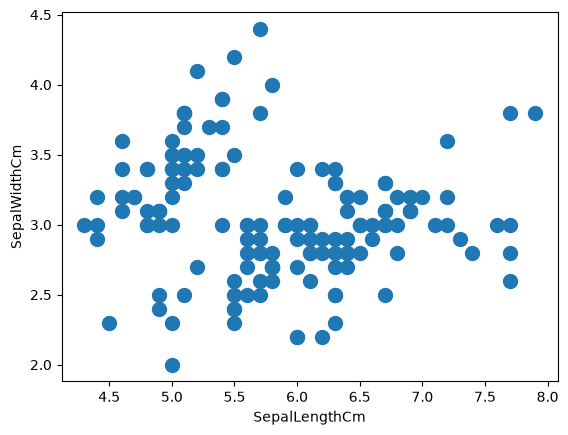

In [7]:
plt.xlabel('SepalLengthCm')
plt.ylabel('SepalWidthCm')
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

## Langkah 5: Membuat model K Means

In [8]:
from sklearn.cluster import KMeans

cl_kmeans = KMeans(n_clusters=2)

y_kmeans = cl_kmeans.fit_predict(X)

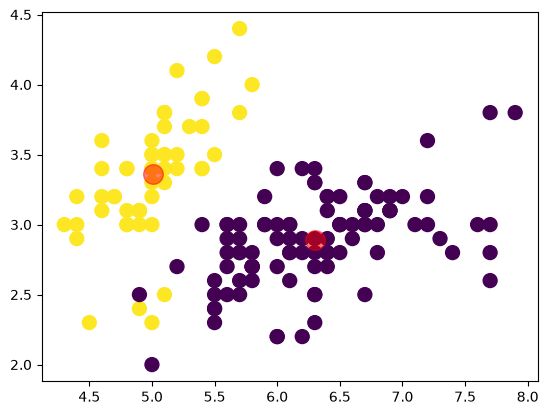

In [9]:
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

## Langkah 6: Evaluasi SSE

In [10]:
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733906


## Langkah 7: Menentukan k dengan elbow method

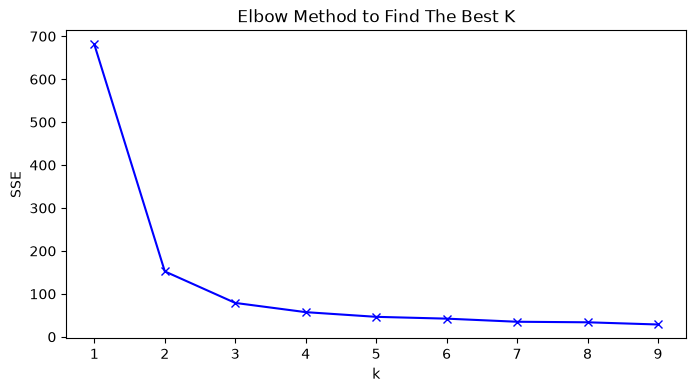

In [11]:
sse = []

K = range(1,10)

for k in K:
 kmeanModel = KMeans(n_clusters=k)
 kmeanModel.fit(X)
 sse.append(kmeanModel.inertia_)

plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()

## Analisis

Grafik siku menunjukkan k=3 sebagai pilihan yang masuk akal. Setelah titik tersebut, penurunan SSE lebih kecil. Nilai SSE dan warna klaster bisa berbeda setiap eksekusi karena inisialisasi centroid pada kode panduan tidak memakai random state.